
# Sales Data Analysis with Python

## Project Overview

This project analyzes sales transaction data using Python and Pandas.

The goal is to understand product performance, total revenue, quantity sold, and transaction patterns to support business decision-making.

## Tools Used
- Python
- Pandas
- Matplotlib
- Google Colab


## Dataset

The dataset contains sales transactions from January 2026.

It includes the following columns:

| Column | Description |
|---|---|
| tanggal | Transaction date |
| produk | Product name |
| jumlah | Quantity sold |
| harga | Price per unit |

The dataset contains 5 transactions involving 3 products: Mouse, Keyboard, and Monitor.



## Data Processing

The dataset was loaded using Pandas.

First, the CSV file was imported and converted into a DataFrame. A new column named `total` was created by multiplying the quantity sold by the unit price.

This column represents the total revenue for each transaction.

### Formula

Total Revenue = Quantity × Unit Price

In [25]:
data_csv = """tanggal,produk,jumlah,harga
2026-01-01,Mouse,2,100000
2026-01-02,Keyboard,1,250000
2026-01-03,Mouse,3,100000
2026-01-04,Keyboard,2,250000
2026-01-05,Monitor,1,1500000
"""

with open("penjualan.csv", "w") as file:
    file.write(data_csv)

print("File berhasil dibuat!")

File berhasil dibuat!


In [26]:
import pandas as pd

df = pd.read_csv("penjualan.csv")

df["total"] = df["jumlah"] * df["harga"]

df.head()

,tanggal,produk,jumlah,harga,total
0,2026-01-01,Mouse,2,100000,200000
1,2026-01-02,Keyboard,1,250000,250000
2,2026-01-03,Mouse,3,100000,300000
3,2026-01-04,Keyboard,2,250000,500000
4,2026-01-05,Monitor,1,1500000,1500000



## Sales Analysis

In this section, sales data is analyzed to identify product performance.

The analysis focuses on:
1. Total revenue for each product.
2. Total quantity sold.
3. Average transaction value.
4. Number of transactions per product.
5. Highest and lowest sales transactions.


In [27]:
# Total revenue by product
revenue_produk = df.groupby("produk")["total"].sum().reset_index()

print(revenue_produk)

     produk    total
0  Keyboard   750000
1   Monitor  1500000
2     Mouse   500000


In [28]:
# Total units sold by product
unit_produk = df.groupby("produk")["jumlah"].sum().reset_index()

print(unit_produk)

     produk  jumlah
0  Keyboard       3
1   Monitor       1
2     Mouse       5


In [29]:
# Average transaction value by product
rata_rata_produk = df.groupby("produk")["total"].mean().reset_index()

print(rata_rata_produk)

     produk      total
0  Keyboard   375000.0
1   Monitor  1500000.0
2     Mouse   250000.0


In [30]:
# Number of transactions by product
jumlah_transaksi = df.groupby("produk")["total"].count().reset_index()

print(jumlah_transaksi)

     produk  total
0  Keyboard      2
1   Monitor      1
2     Mouse      2


In [31]:
summary = df.groupby("produk").agg(
    total_omzet=("total", "sum"),
    total_unit=("jumlah", "sum"),
    rata_rata_transaksi=("total", "mean"),
    jumlah_transaksi=("total", "count")
).reset_index()

print(summary)

     produk  total_omzet  total_unit  rata_rata_transaksi  jumlah_transaksi
0  Keyboard       750000           3             375000.0                 2
1   Monitor      1500000           1            1500000.0                 1
2     Mouse       500000           5             250000.0                 2



## Business Insights

1. Mouse has the highest sales volume, with 5 units sold.
2. Monitor generates the highest revenue, totaling Rp1,500,000, despite selling only 1 unit.
3. Keyboard generates Rp750,000 in revenue from 3 units sold.
4. Mouse generates Rp500,000 in revenue from 5 units sold.

These results indicate that the product with the highest sales volume is not necessarily the product generating the highest revenue.


## Business Recommendations

1. Increase Mouse sales through promotional campaigns, as it has the highest sales volume but relatively low revenue.
2. Offer Mouse and Keyboard bundle packages to encourage customers to purchase both products.
3. Maintain Monitor sales performance, as it generates the highest revenue.
4. Evaluate promotional strategies by monitoring changes in sales volume and revenue.

These recommendations can be tested and evaluated using future sales data.


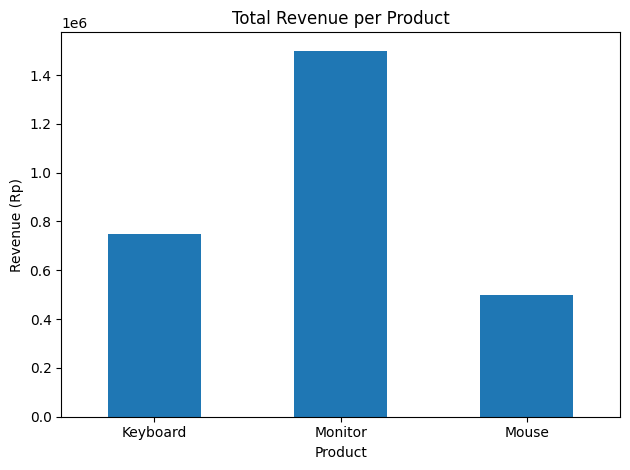

In [32]:
import matplotlib.pyplot as plt

summary.plot(
    x="produk",
    y="total_omzet",
    kind="bar",
    legend=False
)

plt.title("Total Revenue per Product")
plt.xlabel("Product")
plt.ylabel("Revenue (Rp)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

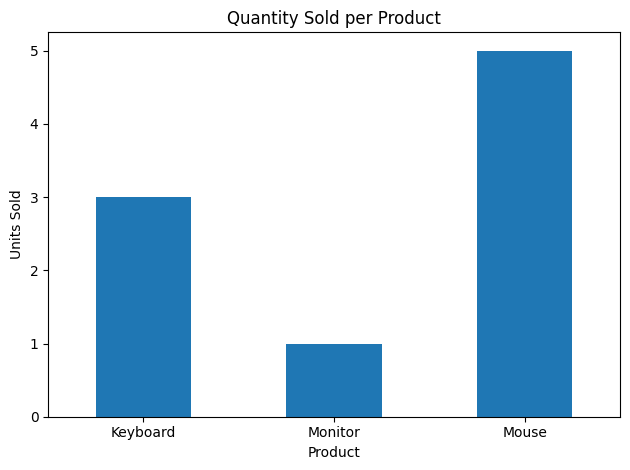

In [33]:
summary.plot(
    x="produk",
    y="total_unit",
    kind="bar",
    legend=False
)

plt.title("Quantity Sold per Product")
plt.xlabel("Product")
plt.ylabel("Units Sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Conclusion

This analysis shows that different products contribute differently to sales performance.

Mouse has the highest sales volume, while Monitor generates the highest revenue.

These findings highlight the importance of analyzing both sales volume and revenue to understand product performance.

Further analysis using a larger dataset and longer sales period could provide more reliable business insights.
